# ms03 阶段 6–8：转移矩阵与 τ、Infomap、每帧标签与时间窗口

输入是 ms02 冻结的 `n_bins`、`D_MAX`；只看开发组，**不用任何行为标记**。

## 阶段 6：转移矩阵与 τ

每个配对集合（F–M1、F–M2、M1–M2，以及合并 F–M1+F–M2 作比较）、每个 τ：所有 t 的 (t, t+τ) 配对（**不是每隔 τ 帧**；论文没说清，要看代码核对），
两帧状态都有效、且在同一连续片段内（审阅判为不可用的片段把轨迹切开，不跨越），汇总到一个矩阵，按行归一化，用稀疏矩阵存。
τ 扫描用对数间隔：`1, 2, 3, 4, 6, 8, 12, 17, 25, 35, 50, 70, 100, 166, 330, 664` 帧（到 4 s）。
每个 τ 记录：Infomap 簇数、最大簇占比（我的理解是占被占用微状态的比例，同时记按帧加权的版本；细节在 SM Fig. S11a，**需核对**）、被占用微状态数、每簇平均含多少微状态、有效配对数、单点簇数。
**τ 的选择**：最大簇占比（按状态数）相邻 τ 之间增幅最大的那一步之前的 τ（τ 太小每个状态自成一簇，太大所有状态连成一簇）。只用聚类结构本身的指标。
扫描时 Infomap 试验次数用 `SCAN_TRIALS = 10`；最终用 500。

**读图时留意**：论文在 τ ≈ 10 帧看到最大簇占比突然跳升；这里（1 组 3 天，约 90 万有效帧对 8000 个状态）曲线形状不同——占比在 τ ≤ 25 一直很低，
M1–M2 在 35→50 帧才有一次明显跳升，τ ≥ 330 时 Infomap 退化成几百个小簇（转移矩阵近似均匀，数据不够）。按规则选出的 τ* 因此比论文大得多，且每个集合不同。
这是与论文不一致的发现，不是要把它调到 12 帧；τ 对不同配对不同也说明规则本身对稀疏数据不稳，结论要看下面的种子稳定性。

In [1]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)


def find_repo_root(start: Path) -> Path:
    for d in [start, *start.parents]:
        if (d / "pyproject.toml").exists() and (d / "scripts" / "common" / "local_paths.py").exists():
            return d
    raise FileNotFoundError("no repository root above " + str(start))


REPO = find_repo_root(Path.cwd().resolve())
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts.analysis import microstate as M

NOTEBOOK = "ms03_transitions_infomap.ipynb"
ROOT = M.roots()
OUT = ROOT["out"]
plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def show(fig, stage, number, name):
    """Write S<stage>_<nn>_<name>.png into the output folder and display it."""
    path = M.save_fig(fig, stage, number, name, NOTEBOOK)
    display(Image(filename=str(path), width=900))
    print("figure:", path)


print("repository:", REPO)
print("figures  ->", OUT)

repository: C:\Users\ReiterU\Documents\GitHub\medaka-mating-pipeline
figures  -> \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap


In [2]:
PARAMS = M.load_params()
S5 = PARAMS["stage5"]
N, DMAX, D_UNIT = S5["n_bins"], S5["dmax_bl"], PARAMS["stage4"]["d_unit"]
NSTATE = N ** 3
DEV = M.trials("dev")
PROC = {e: M.process_trial(e, PARAMS) for e in DEV}
SETS = list(M.PAIR_SETS)
ITEMS = {s: [(M.bin_states(*M.pair_units(P, p, D_UNIT), N, DMAX), P["seg"]) for P in PROC.values() for p in M.PAIR_SETS[s]] for s in SETS}
FR = {s: M.state_frame_counts(ITEMS[s], NSTATE) for s in SETS}
print(f"n = {N} per variable ({NSTATE} states), D_MAX = {DMAX} BL; dev trials {DEV}")
print({s: int(FR[s].sum()) for s in SETS}, "valid frames per set")

n = 20 per variable (8000 states), D_MAX = 9.25 BL; dev trials ['20251225_K_1_1_FCMC', '20251225_K_1_2_FCMC', '20251225_K_1_3_FCMC']
{'F-M1': 897455, 'F-M2': 961838, 'M1-M2': 936228, 'F-M pooled': 1859293} valid frames per set


In [3]:
import time
SCAN_TRIALS = 10
TAUS = list(M.TAU_GRID)
jobs, meta = [], []
for s in SETS:
    for tau in TAUS:
        c, k = M.pooled_counts(ITEMS[s], tau, NSTATE)
        jobs.append((c, SCAN_TRIALS, 0)); meta.append((s, tau, k))
t0 = time.time()
labs = M.infomap_parallel(jobs)
print(f"{len(jobs)} Infomap runs, trials={SCAN_TRIALS}: {time.time() - t0:.0f} s")
LAB_SCAN = {(s, tau): lab for (s, tau, _), lab in zip(meta, labs)}
rows = []
for (s, tau, k), lab in zip(meta, labs):
    rows.append({"set": s, "tau": tau, "tau_s": tau / 166, "effective_pairs": k, **M.cluster_metrics(lab, FR[s])})
scan = pd.DataFrame(rows)
scan.to_csv(OUT / "S6_tau_scan.csv", index=False)
scan.loc[scan["set"] == "F-M1", ["tau", "effective_pairs", "n_clusters", "occupied_states", "largest_state_frac", "largest_frame_frac", "mean_states_per_cluster", "singletons"]].round(4)

64 Infomap runs, trials=10: 72 s


,tau,effective_pairs,n_clusters,occupied_states,largest_state_frac,largest_frame_frac,mean_states_per_cluster,singletons
0,1,896286,3773,7608,0.0014,0.0027,2.0164,1301
1,2,895237,2211,7608,0.0024,0.0055,3.4410,227
2,3,894297,1600,7608,0.0030,0.0067,4.7550,94
3,4,893431,1269,7608,0.0035,0.0094,5.9953,47
4,6,891823,921,7606,0.0053,0.0135,8.2584,19
5,8,890284,742,7606,0.0079,0.0169,10.2507,16
6,12,887443,553,7606,0.0112,0.0334,13.7541,5
7,17,884253,437,7607,0.0174,0.0381,17.4073,3
8,25,880411,388,7608,0.0193,0.0456,19.6082,2
9,35,876268,371,7606,0.0296,0.0630,20.5013,0


F-M1        biggest jump of largest-cluster fraction: tau 50 -> 70 (+0.040)  => tau* = 50 frames (0.301 s)
F-M2        biggest jump of largest-cluster fraction: tau 70 -> 100 (+0.111)  => tau* = 70 frames (0.422 s)
M1-M2       biggest jump of largest-cluster fraction: tau 35 -> 50 (+0.179)  => tau* = 35 frames (0.211 s)
F-M pooled  biggest jump of largest-cluster fraction: tau 70 -> 100 (+0.141)  => tau* = 70 frames (0.422 s)


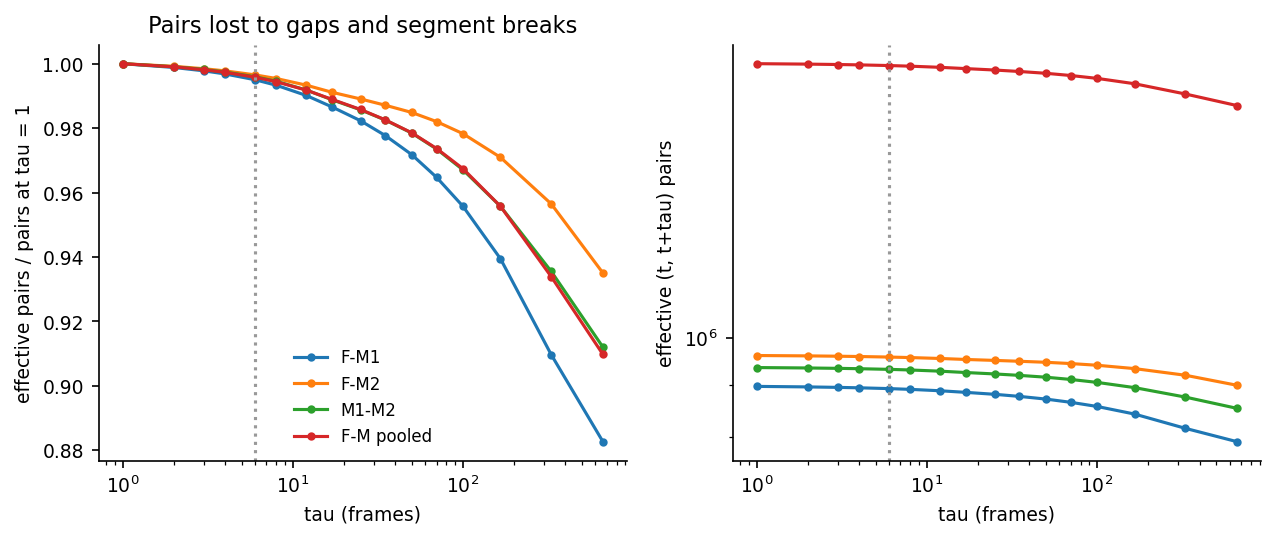

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S6_01_effective_pairs_vs_tau.png


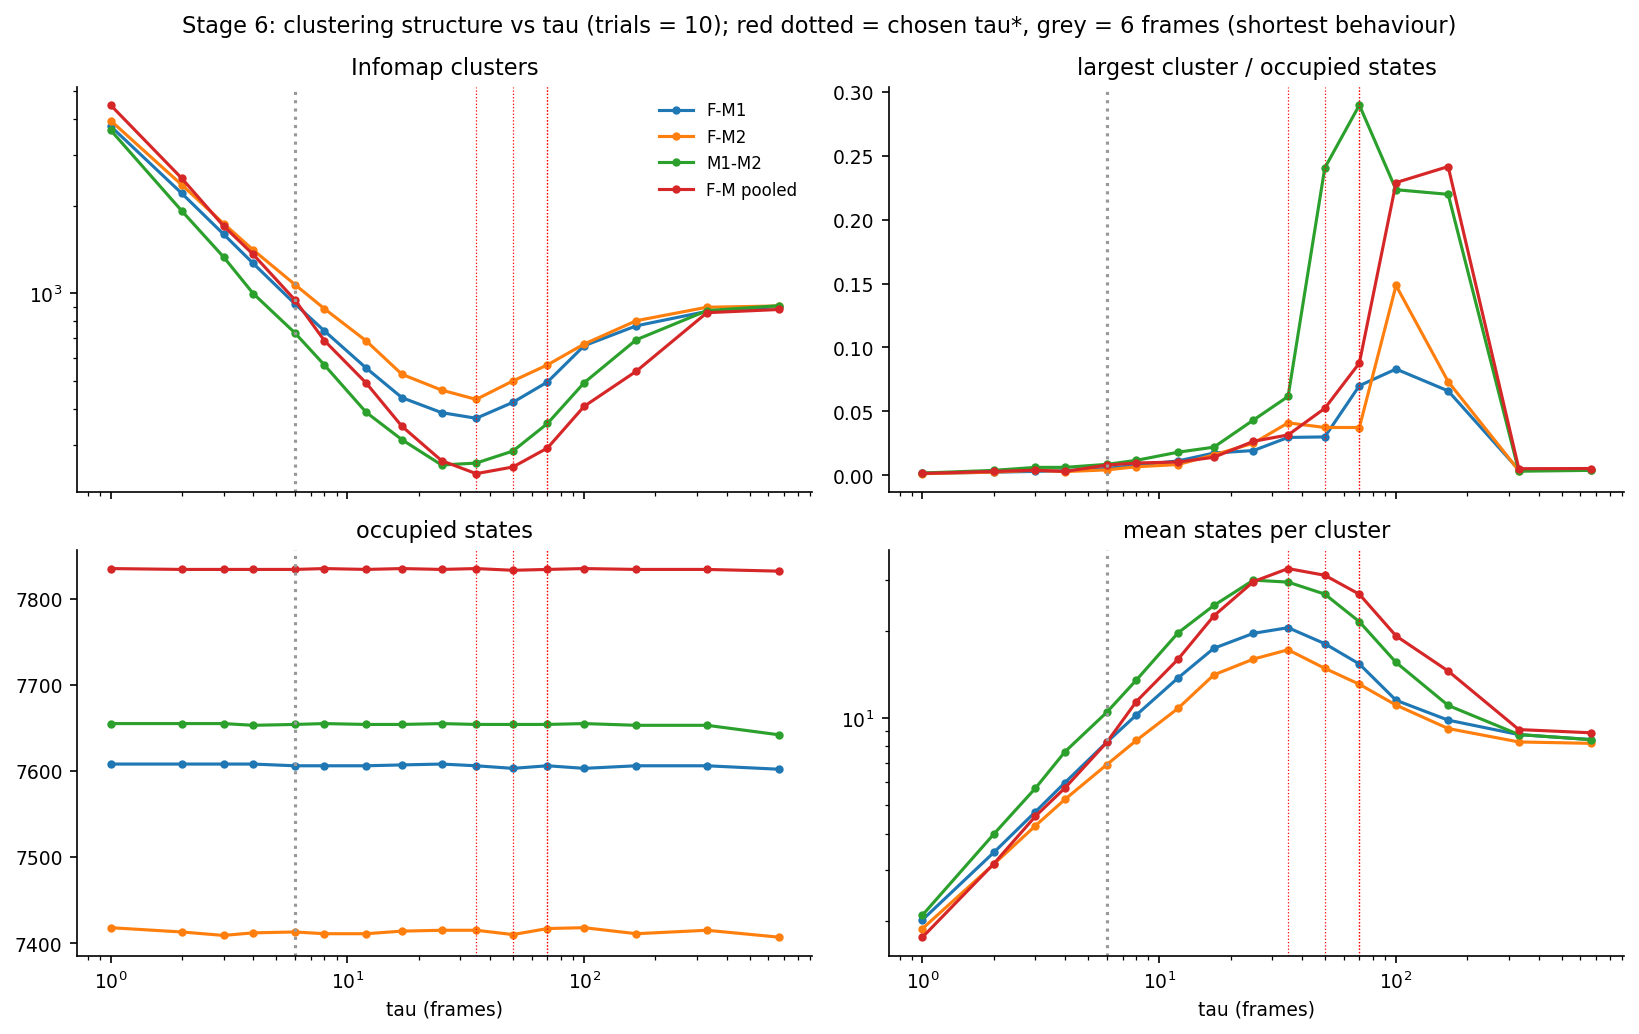

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S6_02_cluster_metrics_vs_tau.png


In [4]:
TAU_STAR_OVERRIDE = {}      # e.g. {"F-M1": 12}
TAU_STAR, JUMP = {}, {}
for s in SETS:
    d = scan[scan["set"] == s].sort_values("tau")
    lf = d["largest_state_frac"].to_numpy()
    j = int(np.argmax(np.diff(lf)))
    TAU_STAR[s] = int(TAU_STAR_OVERRIDE.get(s, d["tau"].iloc[j]))
    JUMP[s] = (int(d["tau"].iloc[j]), int(d["tau"].iloc[j + 1]), float(np.diff(lf)[j]))
    print(f"{s:11s} biggest jump of largest-cluster fraction: tau {JUMP[s][0]} -> {JUMP[s][1]} (+{JUMP[s][2]:.3f})  => tau* = {TAU_STAR[s]} frames ({TAU_STAR[s] / 166:.3f} s)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True)
for s in SETS:
    d = scan[scan["set"] == s]
    axes[0].plot(d["tau"], d["effective_pairs"] / d["effective_pairs"].iloc[0], "-o", ms=3, label=s)
    axes[1].plot(d["tau"], d["effective_pairs"], "-o", ms=3, label=s)
axes[0].set_ylabel("effective pairs / pairs at tau = 1"); axes[1].set_ylabel("effective (t, t+tau) pairs"); axes[1].set_yscale("log")
for a_ in axes: a_.set_xscale("log"); a_.set_xlabel("tau (frames)"); a_.axvline(6, color="0.6", ls=":")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_title("Pairs lost to gaps and segment breaks")
show(fig, 6, 1, "effective_pairs_vs_tau")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for s in SETS:
    d = scan[scan["set"] == s]
    for ax, col in zip(axes.ravel(), ("n_clusters", "largest_state_frac", "occupied_states", "mean_states_per_cluster")):
        ax.plot(d["tau"], d[col], "-o", ms=3, label=s)
for ax, ttl in zip(axes.ravel(), ("Infomap clusters", "largest cluster / occupied states", "occupied states", "mean states per cluster")):
    ax.set_xscale("log"); ax.set_title(ttl); ax.axvline(6, color="0.6", ls=":")
    for s in SETS: ax.axvline(TAU_STAR[s], color="r", ls=":", lw=0.6)
axes[0, 0].set_yscale("log"); axes[1, 1].set_yscale("log"); axes[1, 0].set_xlabel("tau (frames)"); axes[1, 1].set_xlabel("tau (frames)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Stage 6: clustering structure vs tau (trials = {SCAN_TRIALS}); red dotted = chosen tau*, grey = 6 frames (shortest behaviour)")
fig.tight_layout()
show(fig, 6, 2, "cluster_metrics_vs_tau")

**小 τ 与大 τ 的比较**：最短行为约 6 帧，τ 超过它就看不到它。下图是不同 τ 聚类之间的 NMI（按各状态的帧数加权，只比较两边都有标签的状态）。
对角块高 = 这一段 τ 内聚类结构相近；若小 τ（≈6）和 τ* 的 NMI 很低，说明两个时间尺度看到的是不同的结构，值得分别保留。

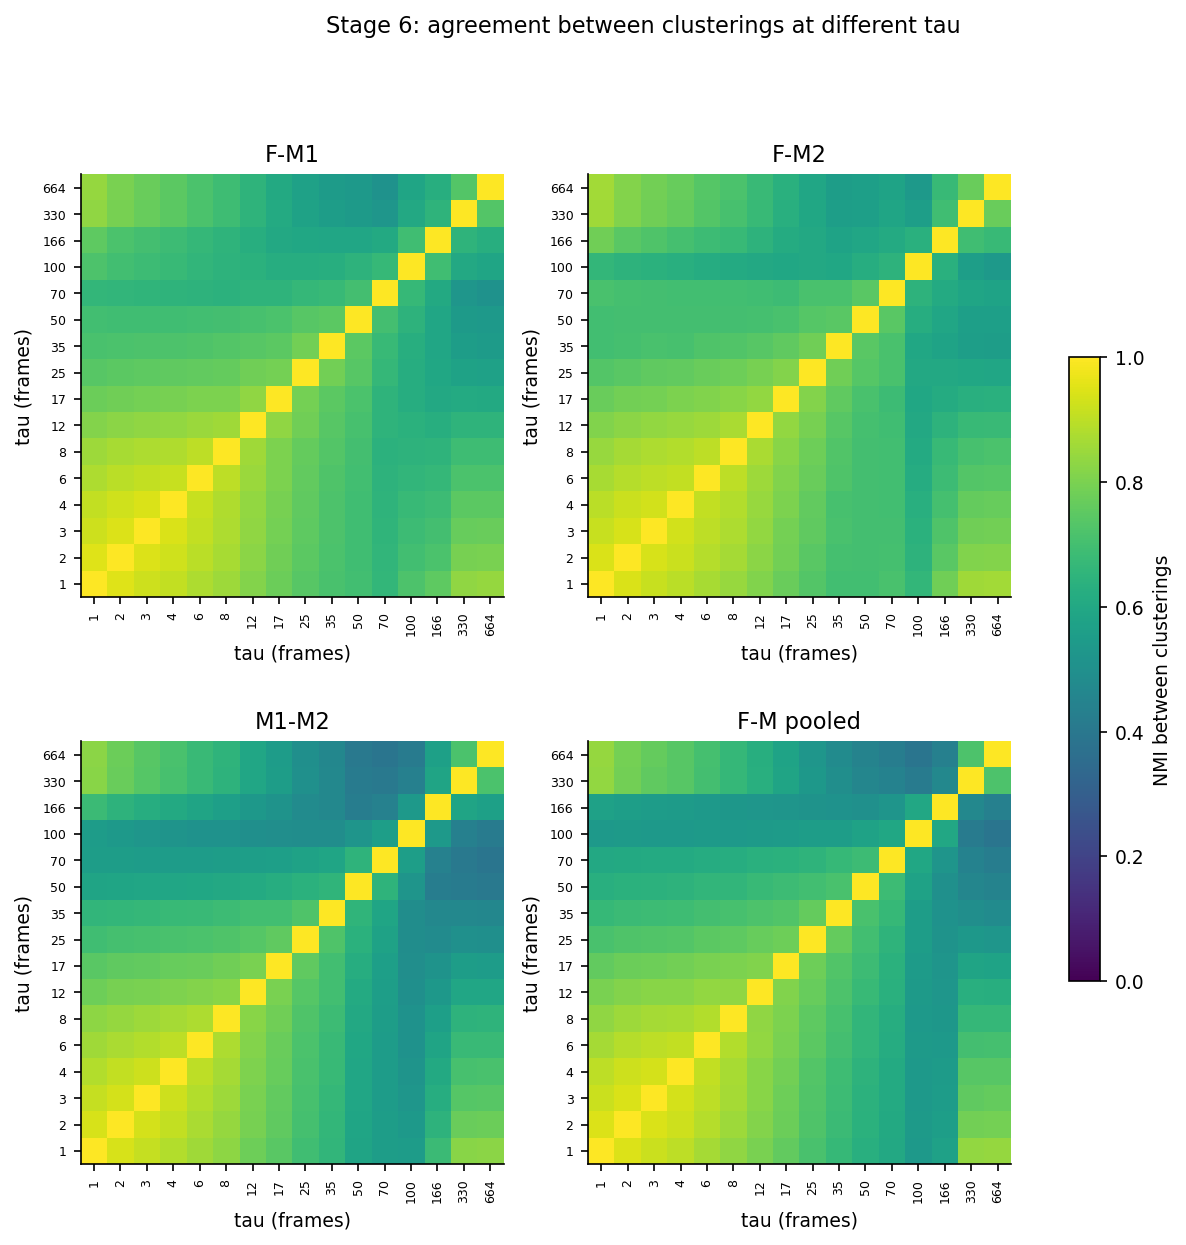

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S6_03_small_vs_large_tau_nmi.png
{'F-M1': 0.697, 'F-M2': 0.699, 'M1-M2': 0.679, 'F-M pooled': 0.62} NMI between tau = 6 and tau* per set


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
NMI_TAU = {}
for ax, s in zip(axes.ravel(), SETS):
    m = np.array([[M.frame_nmi(LAB_SCAN[(s, a)], LAB_SCAN[(s, b)], FR[s]) for b in TAUS] for a in TAUS])
    NMI_TAU[s] = m
    im = ax.imshow(m, vmin=0, vmax=1, cmap="viridis", origin="lower")
    ax.set_xticks(range(len(TAUS))); ax.set_xticklabels(TAUS, rotation=90, fontsize=6)
    ax.set_yticks(range(len(TAUS))); ax.set_yticklabels(TAUS, fontsize=6); ax.set_title(s)
    ax.set_xlabel("tau (frames)"); ax.set_ylabel("tau (frames)")
fig.colorbar(im, ax=axes, shrink=0.6, label="NMI between clusterings")
fig.suptitle("Stage 6: agreement between clusterings at different tau")
show(fig, 6, 3, "small_vs_large_tau_nmi")
i6 = TAUS.index(6)
print({s: round(float(NMI_TAU[s][i6, TAUS.index(TAU_STAR[s])]), 3) for s in SETS}, "NMI between tau = 6 and tau* per set")

## 阶段 7：Infomap（最终）

python-igraph 的 `community_infomap`，边权 = 行归一化转移概率，有向，没出现过的状态不进图，`trials = FINAL_TRIALS`（论文 500），其余默认。
簇数不是设定的，由 τ 和格数决定。用 `N_SEEDS` 个随机种子各跑一次，簇划分用 NMI 互相比较；NMI 低的设置不用（`NMI_MIN = 0.9` 起点）。
这里**保留所有簇**，不按“打斗帧”挑簇（没有这个标签）；右图的“近距离”只是描述每个簇的中位 D，不是筛选规则。
Infomap 单线程，种子在不同进程里并行跑。

20 runs x 500 trials: 20.4 min


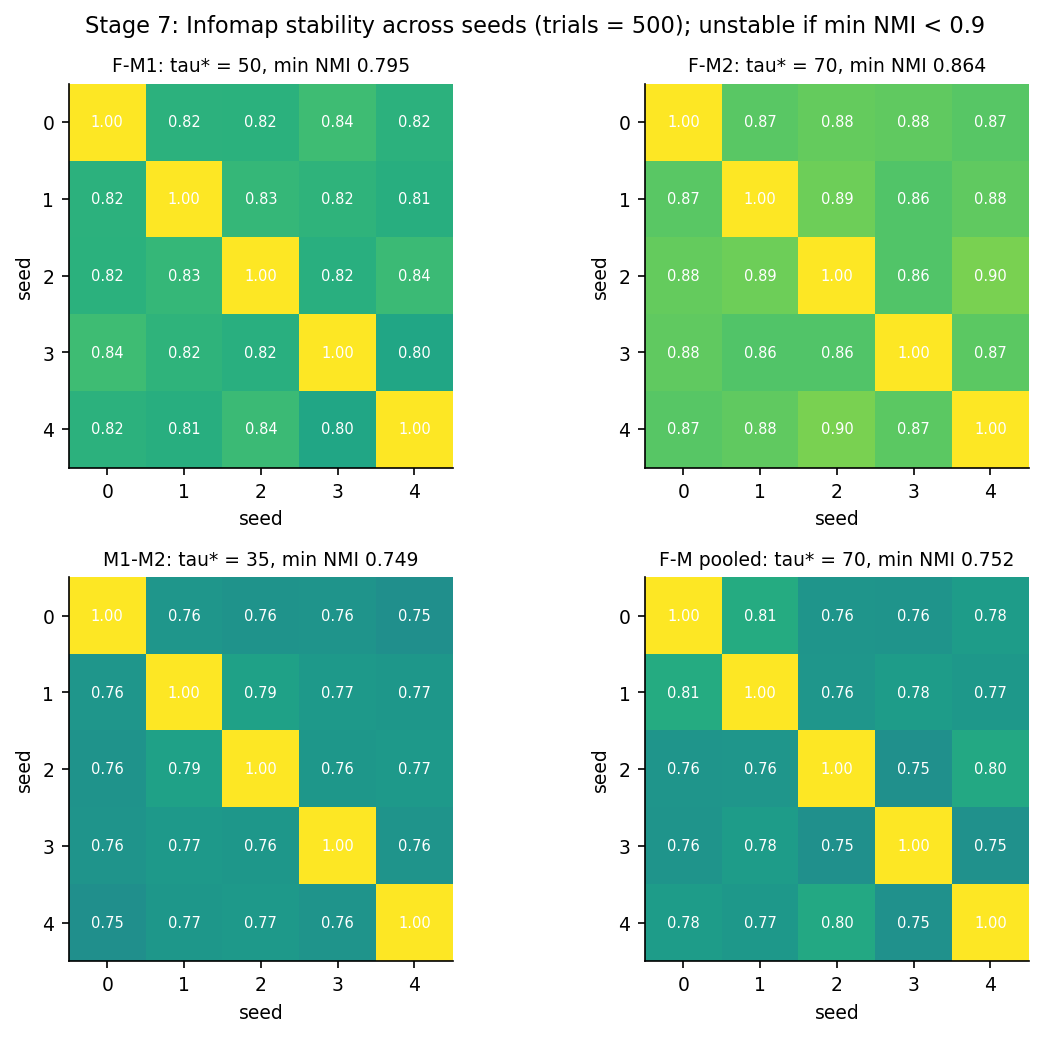

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_01_infomap_seed_stability.png
F-M1        clusters per seed [408, 412, 415, 416, 406]  min NMI 0.795  -> UNSTABLE: do not use as is
F-M2        clusters per seed [583, 583, 580, 571, 561]  min NMI 0.864  -> UNSTABLE: do not use as is
M1-M2       clusters per seed [241, 251, 244, 255, 246]  min NMI 0.749  -> UNSTABLE: do not use as is
F-M pooled  clusters per seed [293, 277, 275, 286, 281]  min NMI 0.752  -> UNSTABLE: do not use as is


In [6]:
FINAL_TRIALS, N_SEEDS, NMI_MIN = 500, 5, 0.90
jobs, meta = [], []
for s in SETS:
    for seed in range(N_SEEDS):
        c, k = M.pooled_counts(ITEMS[s], TAU_STAR[s], NSTATE)
        jobs.append((c, FINAL_TRIALS, seed)); meta.append((s, seed))
t0 = time.time()
labs = M.infomap_parallel(jobs, workers=14)
print(f"{len(jobs)} runs x {FINAL_TRIALS} trials: {(time.time() - t0) / 60:.1f} min")
SEEDS = {s: [lab for (s_, _), lab in zip(meta, labs) if s_ == s] for s in SETS}
LAB = {s: SEEDS[s][0] for s in SETS}
stab = {}
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for ax, s in zip(axes.ravel(), SETS):
    m = np.array([[M.frame_nmi(a, b, FR[s]) for b in SEEDS[s]] for a in SEEDS[s]])
    stab[s] = {"min_nmi": float(m.min()), "n_clusters": [int(len(np.unique(l[l >= 0]))) for l in SEEDS[s]]}
    ax.imshow(m, vmin=0.5, vmax=1, cmap="viridis")
    for i in range(N_SEEDS):
        for j in range(N_SEEDS): ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", color="w", fontsize=7)
    ax.set_title(f"{s}: tau* = {TAU_STAR[s]}, min NMI {m.min():.3f}", fontsize=9)
    ax.set_xlabel("seed"); ax.set_ylabel("seed")
fig.suptitle(f"Stage 7: Infomap stability across seeds (trials = {FINAL_TRIALS}); unstable if min NMI < {NMI_MIN}")
fig.tight_layout()
show(fig, 7, 1, "infomap_seed_stability")
for s in SETS:
    print(f"{s:11s} clusters per seed {stab[s]['n_clusters']}  min NMI {stab[s]['min_nmi']:.3f}  ->", "OK" if stab[s]["min_nmi"] >= NMI_MIN else "UNSTABLE: do not use as is")

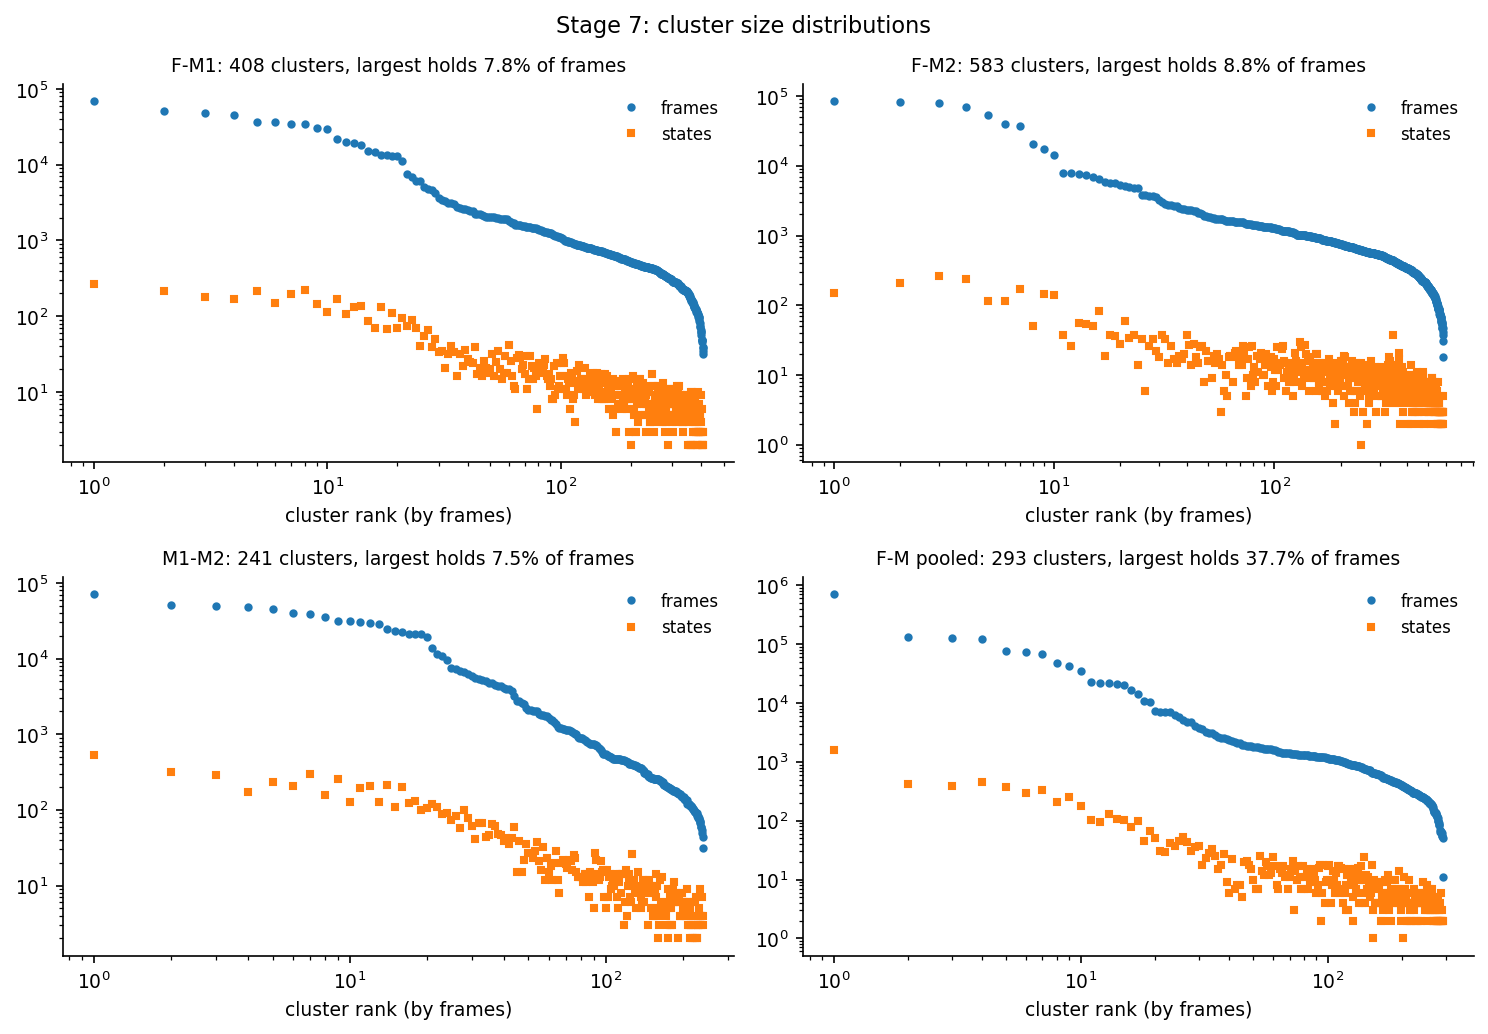

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_02_cluster_size_distribution.png


,set,rank,cluster,states,frames,frame_share,median_D_BL
0,F-M1,1,390,266,69626,0.077582,8.55625
1,F-M1,2,2,213,51066,0.056901,1.15625
2,F-M1,3,259,181,47806,0.053268,7.16875
3,F-M1,4,388,171,45707,0.050930,8.55625
4,F-M1,5,231,216,37102,0.041341,6.24375
408,F-M2,1,6,151,84996,0.088368,0.69375
409,F-M2,2,15,211,81907,0.085157,1.61875
410,F-M2,3,42,266,78042,0.081138,1.15625
411,F-M2,4,20,241,69356,0.072108,1.15625
412,F-M2,5,7,116,53452,0.055573,0.69375


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
cl_rows = []
for ax, s in zip(axes.ravel(), SETS):
    lab = LAB[s]; used = lab >= 0
    k = lab[used]
    states_per = np.bincount(k); frames_per = np.bincount(k, weights=FR[s][used])
    order = np.argsort(-frames_per)
    ax.loglog(np.arange(1, len(order) + 1), frames_per[order], "o", ms=3, label="frames")
    ax.loglog(np.arange(1, len(order) + 1), states_per[order], "s", ms=3, label="states")
    ax.set_title(f"{s}: {len(order)} clusters, largest holds {frames_per.max() / frames_per.sum():.1%} of frames", fontsize=9)
    ax.set_xlabel("cluster rank (by frames)"); ax.legend(frameon=False, fontsize=8)
    di = (np.arange(NSTATE) // (N * N))
    for rank, c in enumerate(order):
        m = lab == c
        w = FR[s][m]
        dd = (di[m] + 0.5) * DMAX / N
        cl_rows.append({"set": s, "rank": rank + 1, "cluster": int(c), "states": int(m.sum()), "frames": int(w.sum()),
                        "frame_share": float(w.sum() / FR[s].sum()), "median_D_BL": float(dd[np.argsort(dd)][np.searchsorted(np.cumsum(w[np.argsort(dd)]), w.sum() / 2)])})
fig.suptitle("Stage 7: cluster size distributions")
fig.tight_layout()
show(fig, 7, 2, "cluster_size_distribution")
CL = pd.DataFrame(cl_rows); CL.to_csv(OUT / "S7_cluster_summary.csv", index=False)
CL.groupby("set").head(5)

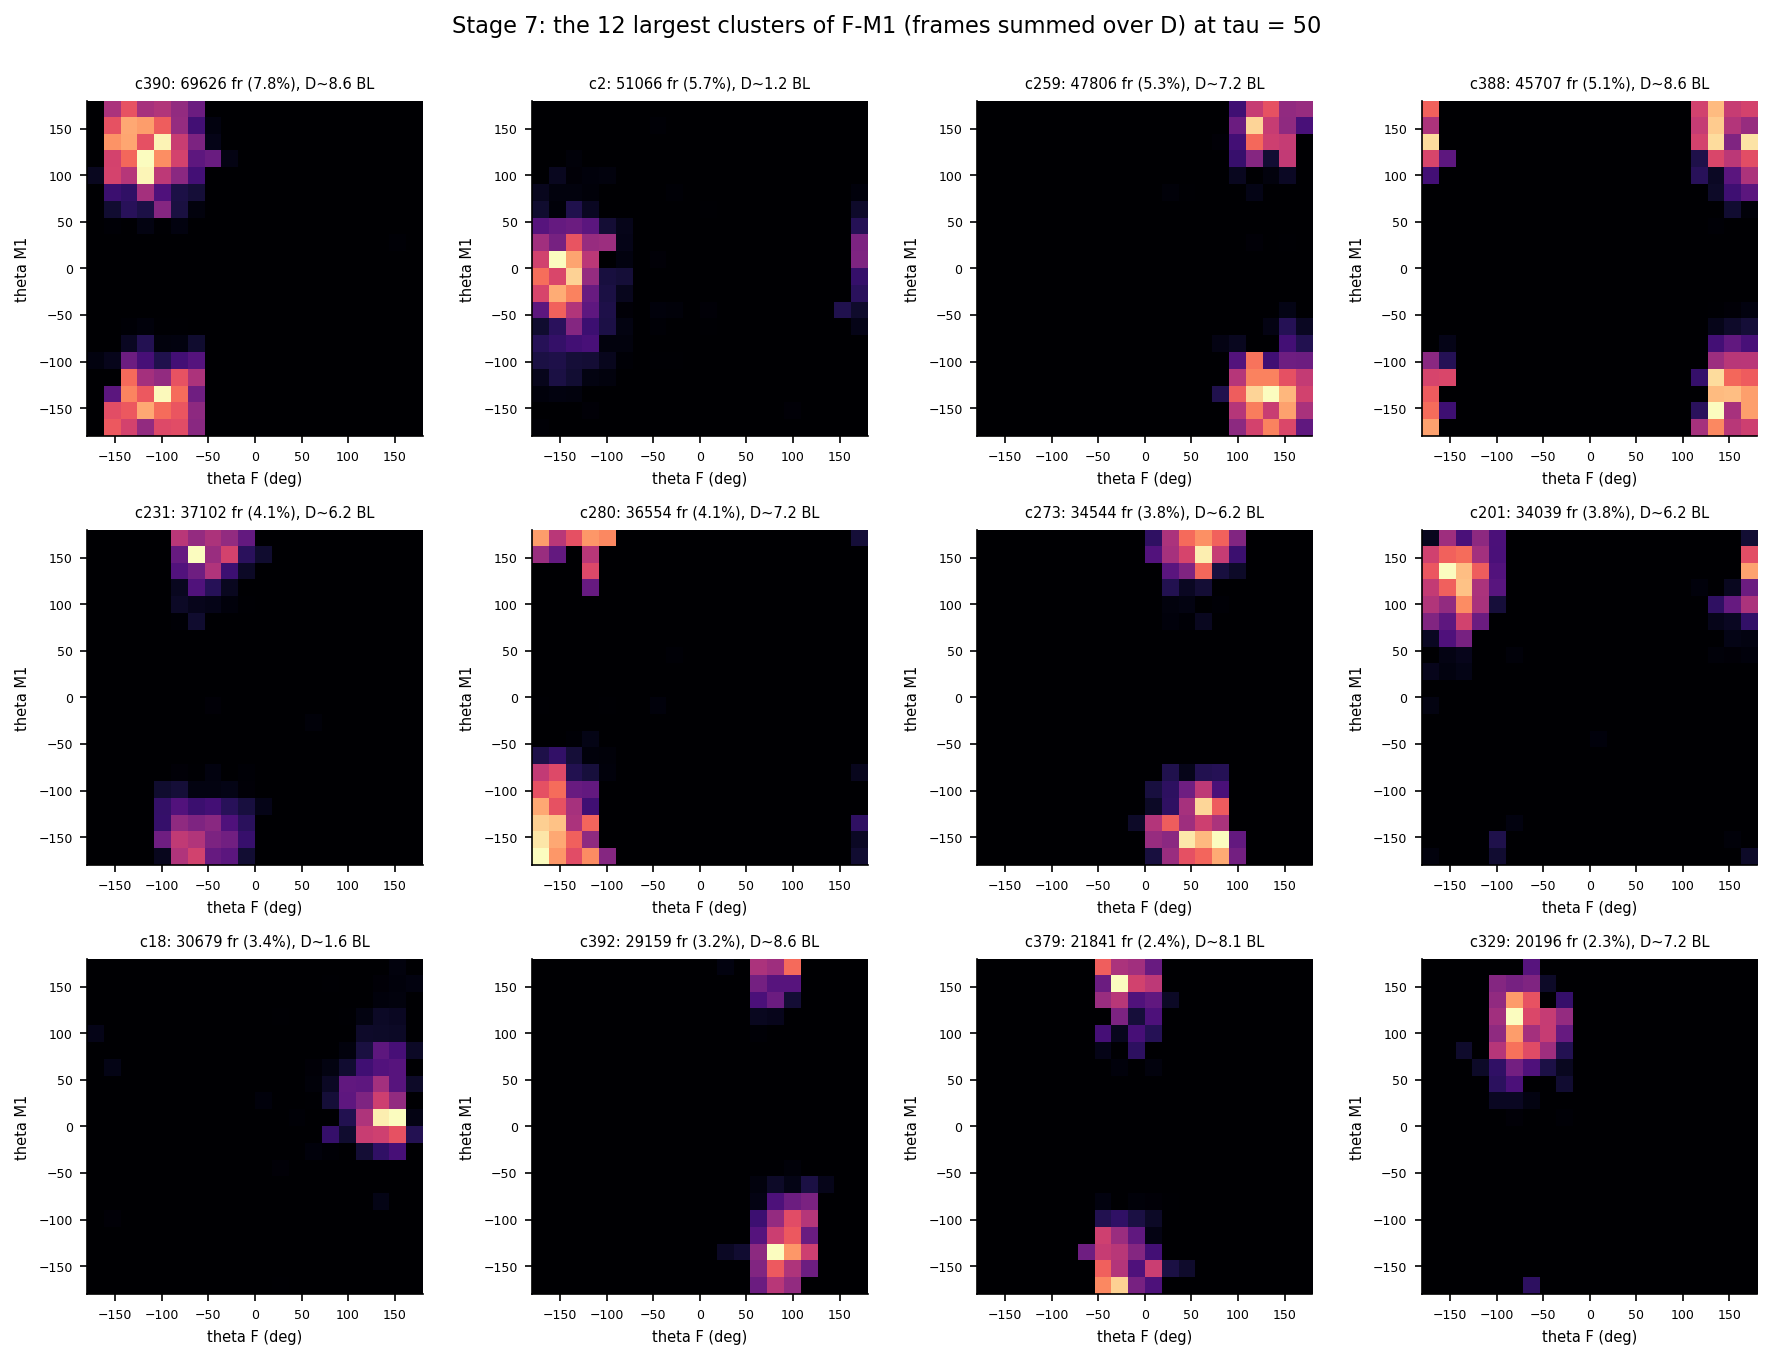

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_03_cluster_gallery_F-M1.png


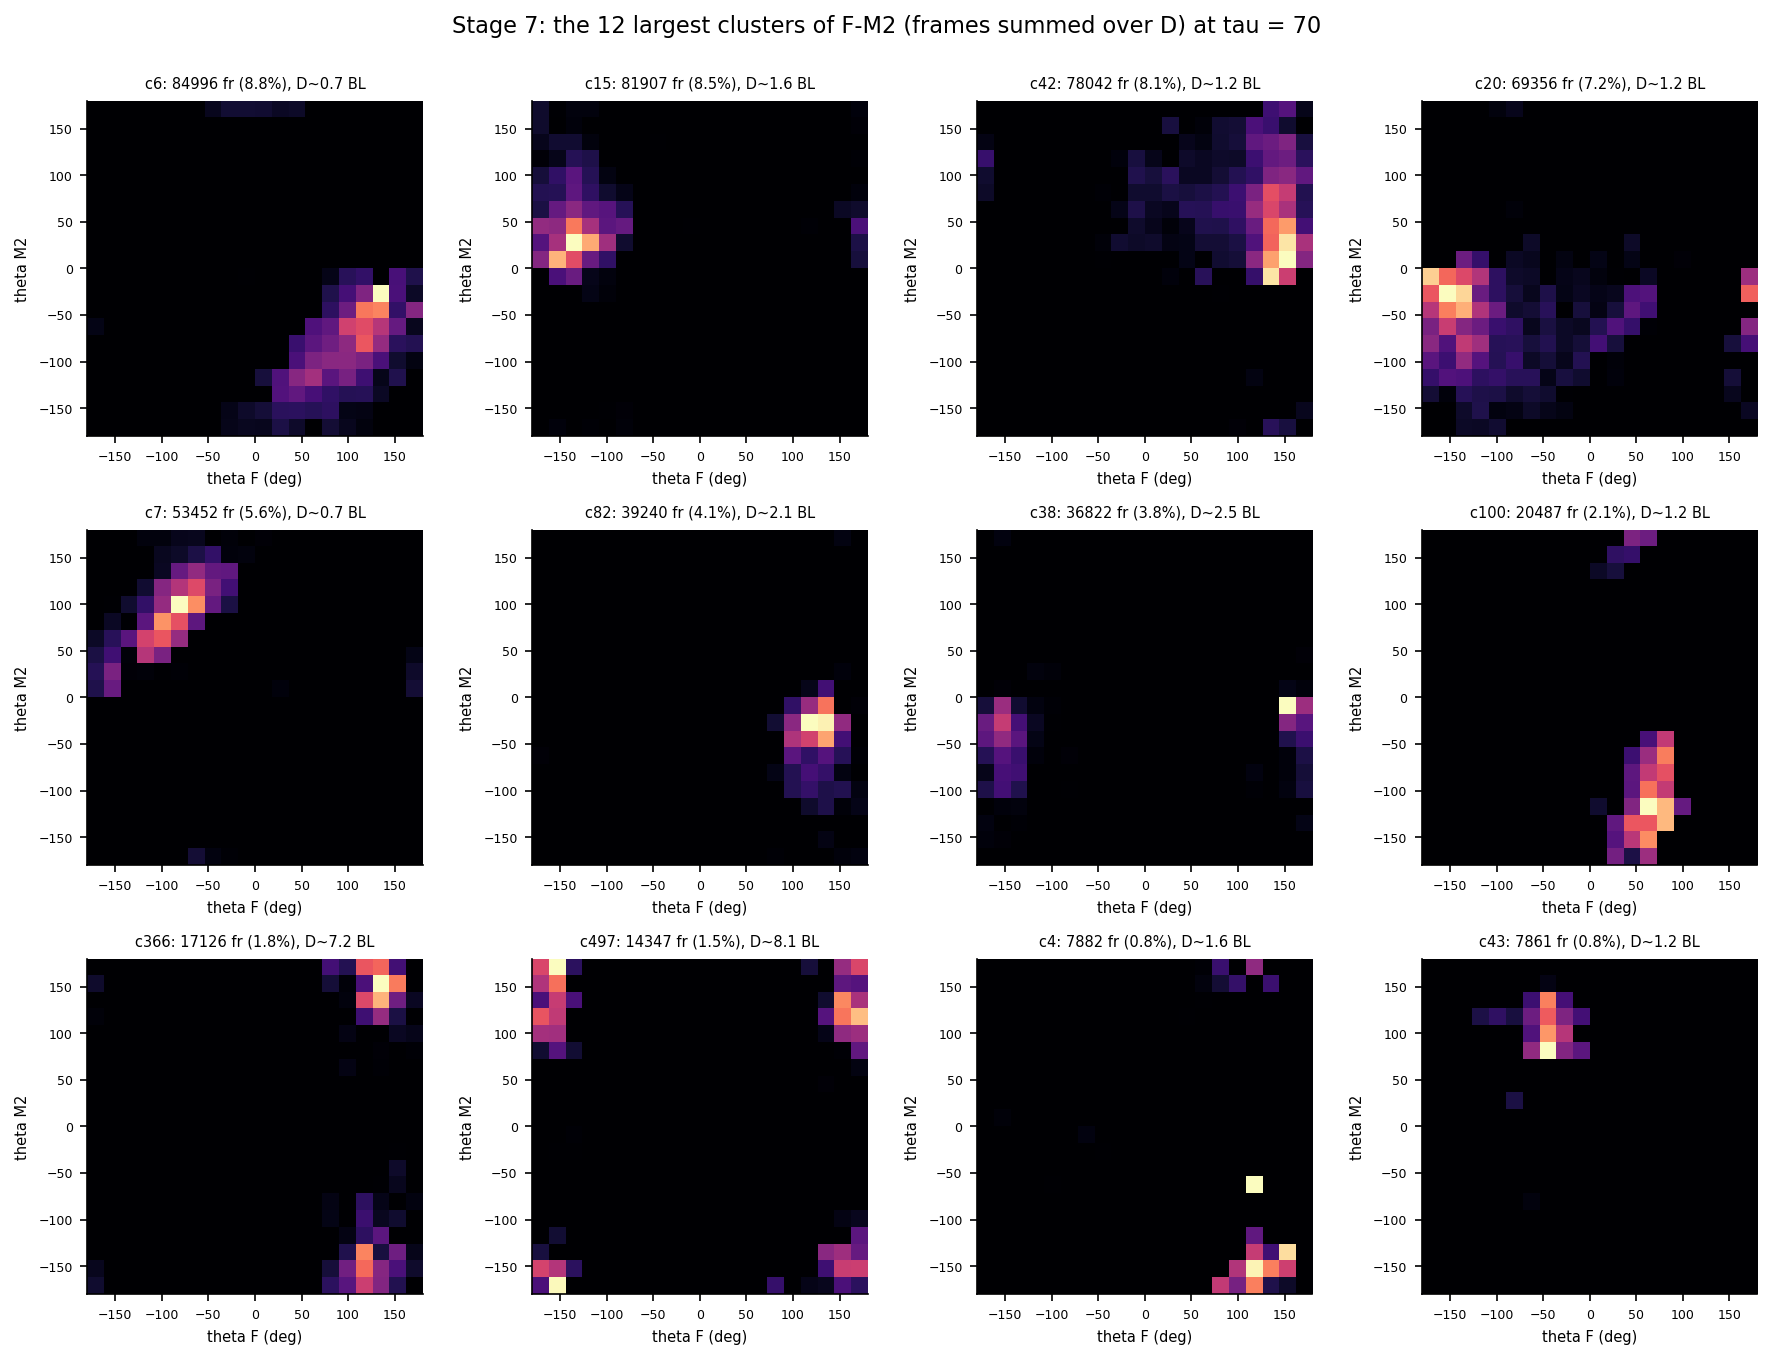

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_04_cluster_gallery_F-M2.png


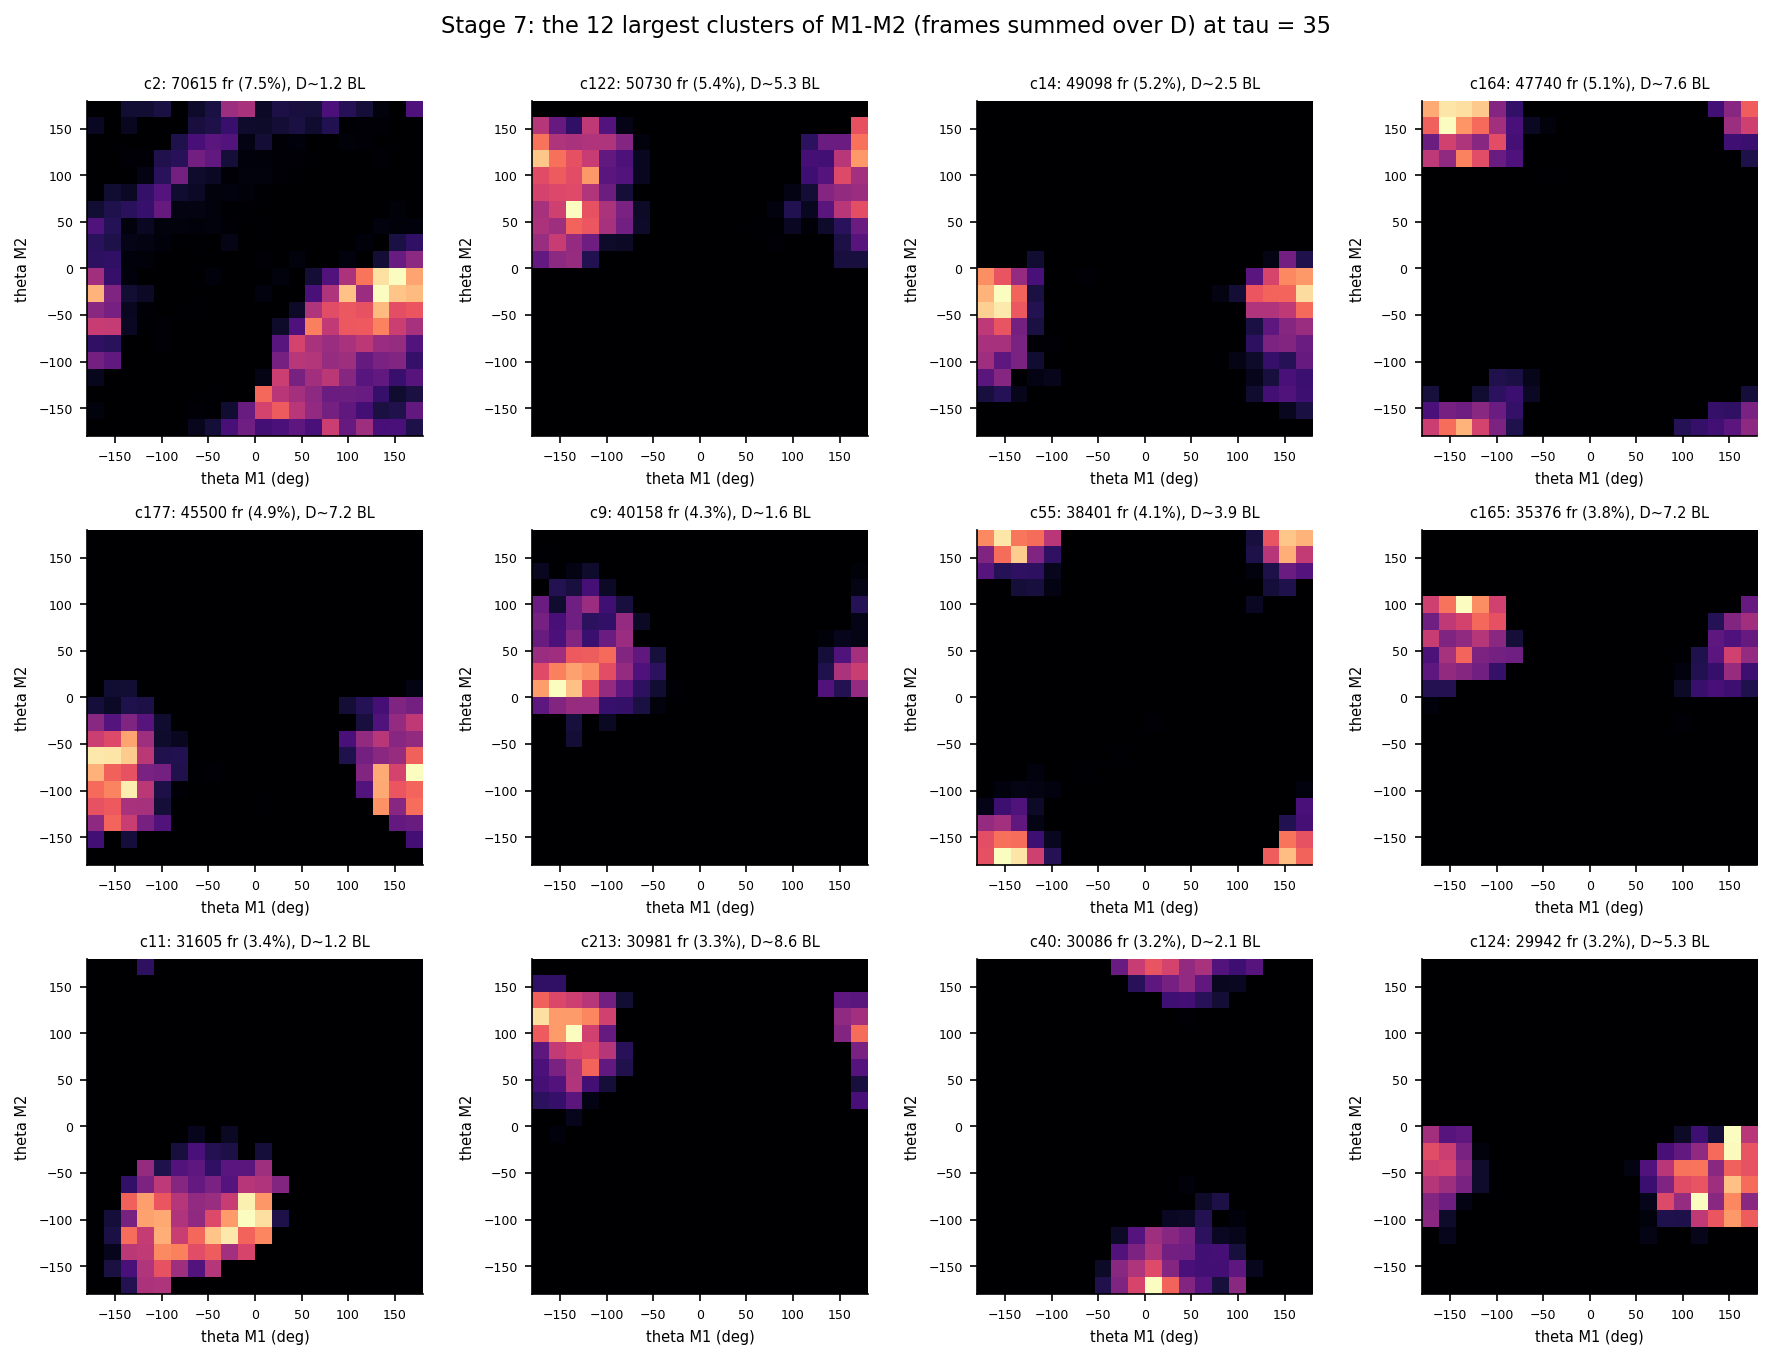

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_05_cluster_gallery_M1-M2.png


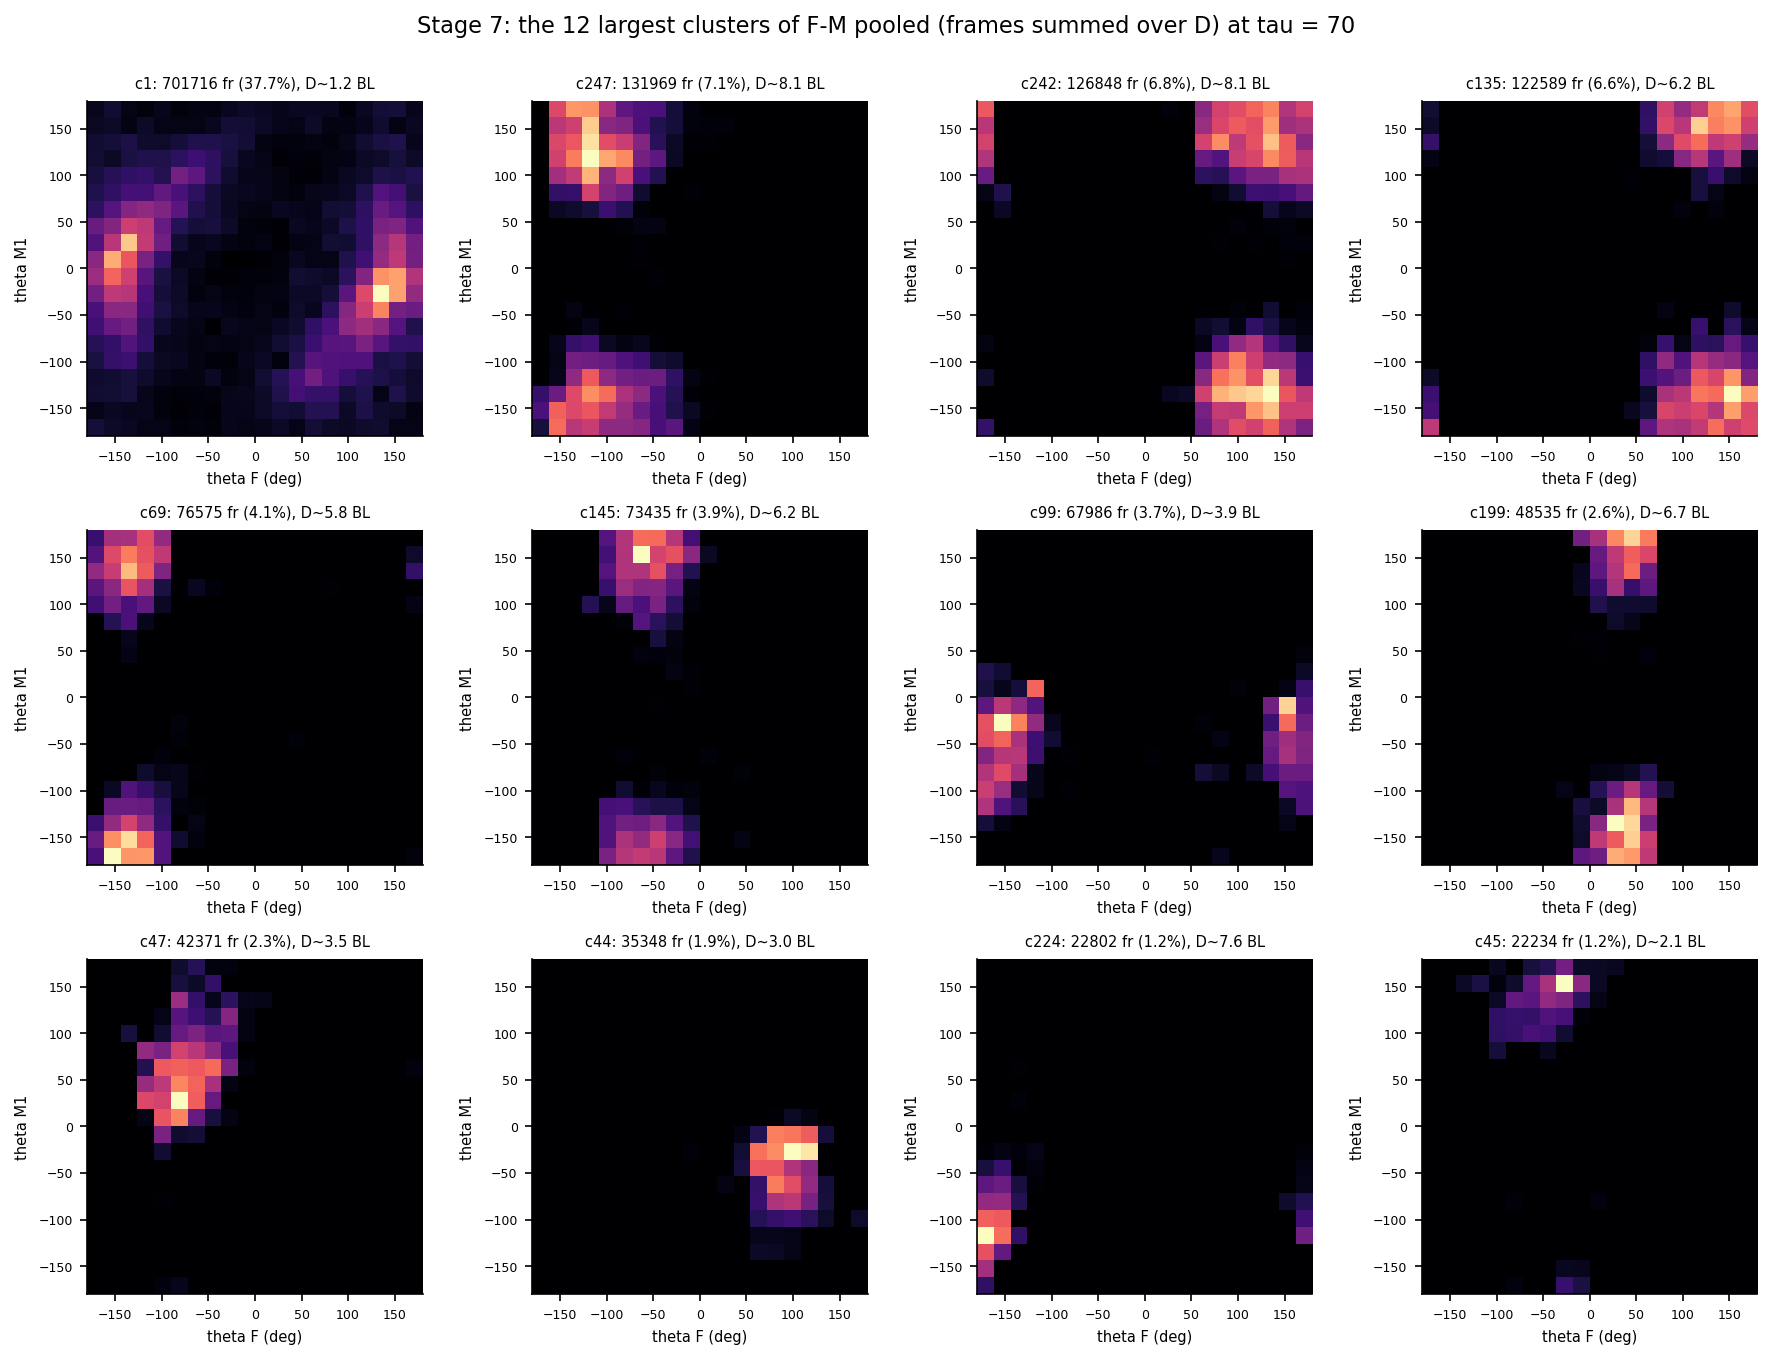

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_06_cluster_gallery_F-M_pooled.png


In [8]:
def gallery(s, number, top=12):
    lab = LAB[s]
    d = CL[CL["set"] == s].head(top)
    cols = 4; rows_ = int(np.ceil(len(d) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3 * cols, 3 * rows_), squeeze=False)
    a_name, b_name = M.PAIR_SETS[s][0].split("-")
    for ax in axes.ravel(): ax.axis("off")
    for ax, r in zip(axes.ravel(), d.itertuples()):
        idx = np.flatnonzero(lab == r.cluster)
        H = np.zeros((N, N))
        np.add.at(H, ((idx // N) % N, idx % N), FR[s][idx])
        ax.axis("on")
        ax.imshow(H.T, origin="lower", extent=[-180, 180, -180, 180], cmap="magma")
        ax.set_title(f"c{r.cluster}: {r.frames} fr ({r.frame_share:.1%}), D~{r.median_D_BL:.1f} BL", fontsize=7)
        ax.set_xlabel(f"theta {a_name} (deg)", fontsize=7); ax.set_ylabel(f"theta {b_name}", fontsize=7); ax.tick_params(labelsize=6)
    fig.suptitle(f"Stage 7: the {len(d)} largest clusters of {s} (frames summed over D) at tau = {TAU_STAR[s]}", y=1.0)
    fig.tight_layout()
    show(fig, 7, number, f"cluster_gallery_{s.replace(' ', '_')}")

for k, s in enumerate(SETS):
    gallery(s, 3 + k)

In [9]:
np.savez_compressed(ROOT["data"] / "clusters.npz", **{f"{s}|labels": LAB[s] for s in SETS}, **{f"{s}|frames": FR[s] for s in SETS})
M.update_params("stage6", {"tau_grid": TAUS, "scan_trials": SCAN_TRIALS, "tau_star": TAU_STAR, "jump": {s: list(v) for s, v in JUMP.items()},
                           "rule": "tau before the largest step-to-step increase of the largest-cluster fraction (of occupied states)"})
M.update_params("stage7", {"final_trials": FINAL_TRIALS, "n_seeds": N_SEEDS, "nmi_min": NMI_MIN, "stability": stab, "seed_used": 0,
                           "n_bins": N, "dmax_bl": DMAX, "tau": TAU_STAR, "d_unit": D_UNIT})
print({s: (TAU_STAR[s], stab[s]["min_nmi"]) for s in SETS})

{'F-M1': (50, 0.7954025106085719), 'F-M2': (70, 0.8637935918536747), 'M1-M2': (35, 0.749495507891148), 'F-M pooled': (70, 0.7515284293856112)}


### 敏感性：格数 n × τ 的稳定性

最终设置若在种子间不稳定，下面用同一套规则（只看聚类自身的稳定性，不看标记）扫 n ∈ {10, 15, 20} 和 τ ∈ {12, 35, 70}：每个组合 3 个种子、`GRID_TRIALS = 50` 次试验，报告种子间最小 NMI 和簇数。
这是“哪个设置值得用”的依据；采用别的 n 要在 ms02 里改 `N_BINS_OVERRIDE` 后重跑，不在这里悄悄换。

108 runs: 4.0 min


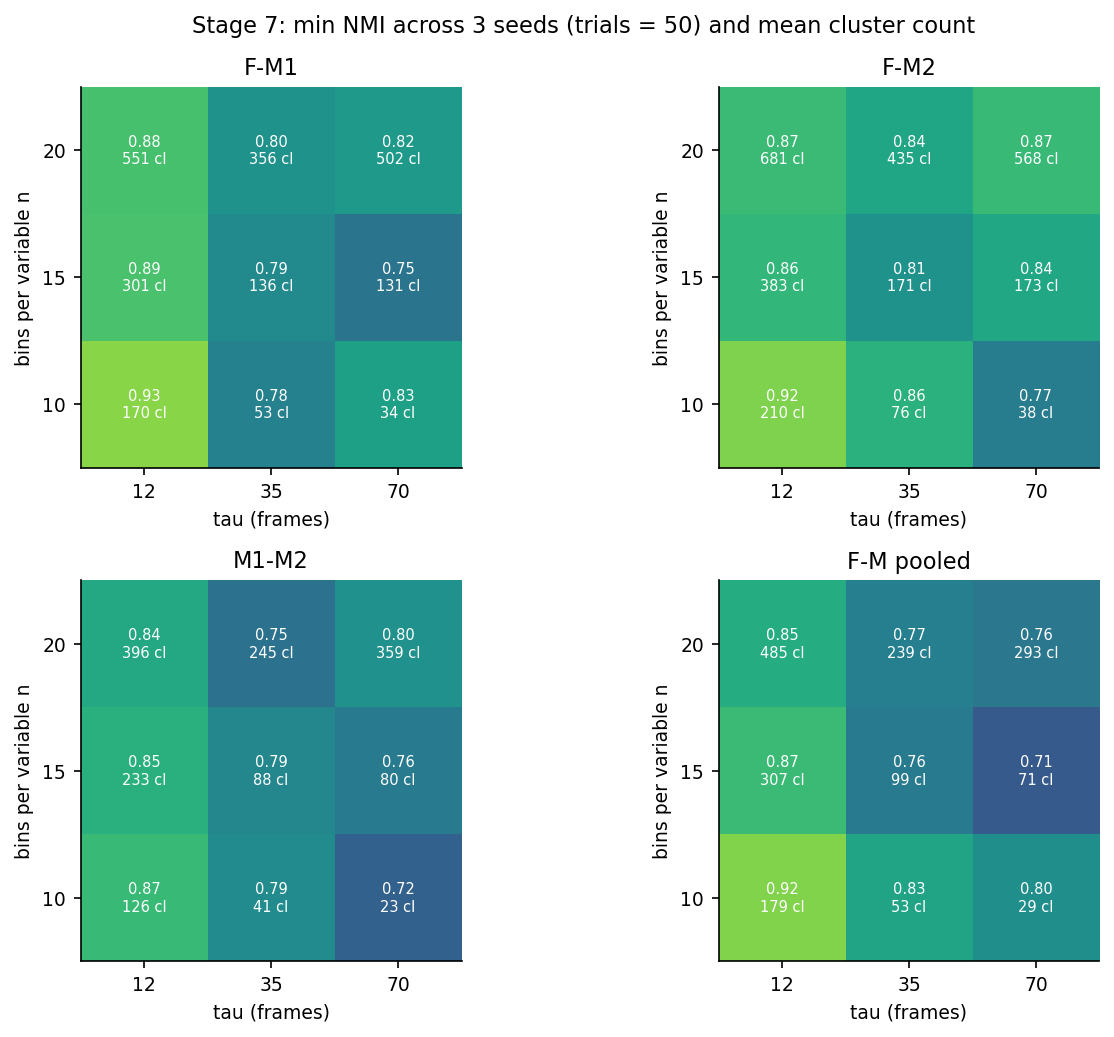

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S7_07_stability_grid_n_by_tau.png


tau               12     35     70
set        n                      
F-M pooled 10  0.925  0.833  0.799
           15  0.873  0.764  0.714
           20  0.848  0.772  0.758
F-M1       10  0.929  0.776  0.827
           15  0.886  0.792  0.754
           20  0.883  0.803  0.816
F-M2       10  0.922  0.855  0.768
           15  0.865  0.806  0.839
           20  0.872  0.835  0.870
M1-M2      10  0.870  0.793  0.724
           15  0.853  0.786  0.764
           20  0.841  0.749  0.803

In [10]:
GRID_N, GRID_TAU, GRID_SEEDS, GRID_TRIALS = (10, 15, 20), (12, 35, 70), 3, 50
jobs, meta, grid_fr = [], [], {}
for n in GRID_N:
    for s in SETS:
        items = [(M.bin_states(*M.pair_units(P, p, D_UNIT), n, DMAX), P["seg"]) for P in PROC.values() for p in M.PAIR_SETS[s]]
        grid_fr[(n, s)] = M.state_frame_counts(items, n ** 3)
        for tau in GRID_TAU:
            c, _ = M.pooled_counts(items, tau, n ** 3)
            for seed in range(GRID_SEEDS):
                jobs.append((c, GRID_TRIALS, seed)); meta.append((n, s, tau, seed))
t0 = time.time()
glabs = M.infomap_parallel(jobs, workers=14)
print(f"{len(jobs)} runs: {(time.time() - t0) / 60:.1f} min")
grid_rows = []
for n in GRID_N:
    for s in SETS:
        for tau in GRID_TAU:
            L = [l for (n_, s_, t_, _), l in zip(meta, glabs) if (n_, s_, t_) == (n, s, tau)]
            m = np.array([[M.frame_nmi(a, b, grid_fr[(n, s)]) for b in L] for a in L])
            grid_rows.append({"n": n, "set": s, "tau": tau, "min_nmi": float(m.min()), "n_clusters": float(np.mean([len(np.unique(l[l >= 0])) for l in L])),
                              **{k: v for k, v in M.cluster_metrics(L[0], grid_fr[(n, s)]).items() if k in ("largest_state_frac", "mean_states_per_cluster")}})
grid = pd.DataFrame(grid_rows); grid.to_csv(OUT / "S7_stability_grid.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, s in zip(axes.ravel(), SETS):
    g = grid[grid["set"] == s]
    mat = g.pivot(index="n", columns="tau", values="min_nmi"); nc = g.pivot(index="n", columns="tau", values="n_clusters")
    ax.imshow(mat.values, vmin=0.6, vmax=1, cmap="viridis", origin="lower")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]): ax.text(j, i, f"{mat.values[i, j]:.2f}\n{nc.values[i, j]:.0f} cl", ha="center", va="center", color="w", fontsize=7)
    ax.set_xticks(range(len(GRID_TAU))); ax.set_xticklabels(GRID_TAU); ax.set_yticks(range(len(GRID_N))); ax.set_yticklabels(GRID_N)
    ax.set_xlabel("tau (frames)"); ax.set_ylabel("bins per variable n"); ax.set_title(s)
fig.suptitle(f"Stage 7: min NMI across {GRID_SEEDS} seeds (trials = {GRID_TRIALS}) and mean cluster count")
fig.tight_layout()
show(fig, 7, 7, "stability_grid_n_by_tau")
grid.pivot_table(index=["set", "n"], columns="tau", values="min_nmi").round(3)

**稳定性网格的读法（K_1 三天，trials = 50，3 个种子）**：种子间最小 NMI 随 τ 增大而下降，随 n 减小而上升。
按阶段 6 规则选出的 τ*（35–70 帧）、n = 20 在所有组合里属于较不稳定的一类（min NMI 0.75–0.87）；
最稳定的是 **n = 10、τ = 12 帧**（F–M1 / F–M2 / 合并 F–M 约 0.92–0.93，M1–M2 约 0.87），其次是 n = 15、τ = 12。
没有任何组合达到 `NMI_MIN = 0.90` 的全部集合。**这个网格没有自动改变上面的最终设置**——最终聚类与 ms04 的命名仍然基于 n = 20、τ*，并在输出中标为不稳定。
想用 n = 10：ms02 里把 `N_BINS_OVERRIDE = 10`，再重跑 ms02 → ms03（τ 也要在 ms03 里用 `TAU_STAR_OVERRIDE` 指定为 12）→ ms04。

## 阶段 8：每帧标签与时间窗口

每帧落在哪个格子就属于哪个簇；超出 D_MAX、角为空或没出现过的格子标“未分配”（−1）。
时间窗口用来看簇出现概率随时间变化。窗口取比变量**相关时间长约一个数量级**：先算 D 和 cos θ 的自相关函数（只用同一连续片段内的帧对），
相关时间 τ_c = 自相关首次降到 1/e 的滞后；`WINDOW_S = 10 × τ_c 的中位数`，限制在 [10 s, 300 s]。你的视频只有约 35 分钟，窗口太长则窗口数太少。

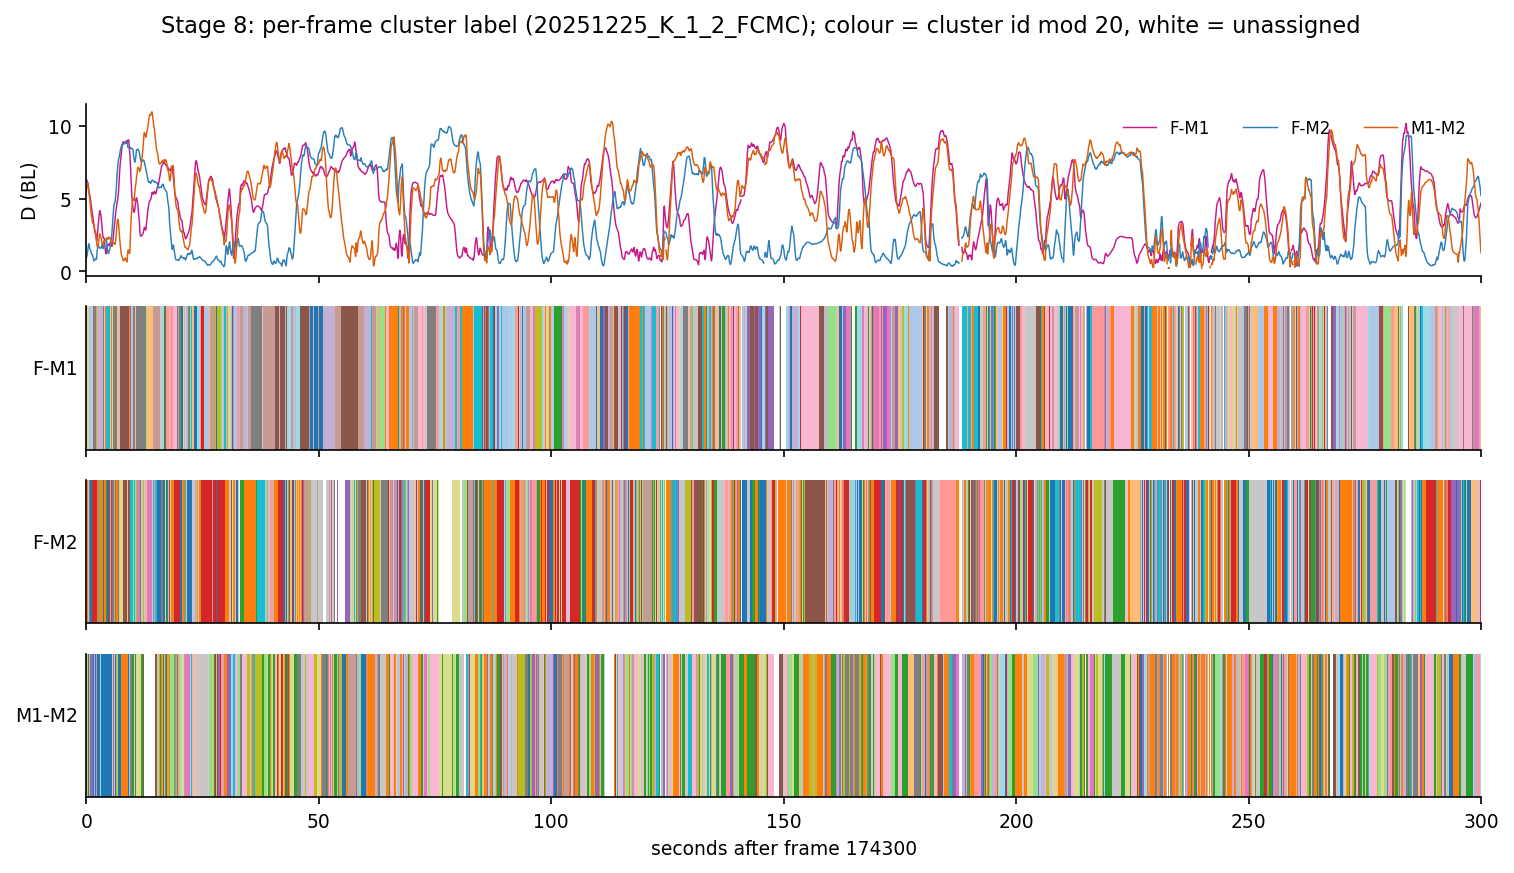

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S8_01_frame_label_timeline_5min.png
{'F-M1': 0.865, 'F-M2': 0.923, 'M1-M2': 0.897} share of all frames assigned in 20251225_K_1_2_FCMC


In [11]:
LABF = {}
for e, P in PROC.items():
    for pair in M.PAIR_NAMES:
        st = M.bin_states(*M.pair_units(P, pair, D_UNIT), N, DMAX)
        LABF[(e, pair)] = np.where(st >= 0, LAB[pair][np.maximum(st, 0)], -1)
EX = DEV[1]; P = PROC[EX]; fps = P["fps"]
W = int(300 * fps)
best_s = max(range(0, len(P["seg"]) - W, W // 2), key=lambda s0: np.mean([np.mean(LABF[(EX, p)][s0:s0 + W] >= 0) for p in M.PAIR_NAMES]))
from matplotlib.colors import ListedColormap
cmap = ListedColormap(plt.cm.tab20.colors)
fig, axes = plt.subplots(4, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1, 1]})
tt = np.arange(W) / fps
for pair, c in zip(M.PAIR_NAMES, ("#c51b8a", "#2c7fb8", "#d95f0e")):
    axes[0].plot(tt[::10], M.pair_units(P, pair, D_UNIT)[0][best_s:best_s + W][::10], lw=0.7, color=c, label=pair)
axes[0].set_ylabel("D (BL)"); axes[0].legend(frameon=False, ncol=3, fontsize=8, loc="upper right")
for ax, pair in zip(axes[1:], M.PAIR_NAMES):
    seq = LABF[(EX, pair)][best_s:best_s + W].astype(float)
    seq[seq < 0] = np.nan
    ax.imshow((seq % 20)[None, ::5], aspect="auto", cmap=cmap, vmin=0, vmax=19, extent=[0, W / fps, 0, 1], interpolation="nearest")
    ax.set_yticks([]); ax.set_ylabel(pair, rotation=0, ha="right")
axes[-1].set_xlabel(f"seconds after frame {P['frames'][best_s]}")
fig.suptitle(f"Stage 8: per-frame cluster label ({EX}); colour = cluster id mod 20, white = unassigned")
show(fig, 8, 1, "frame_label_timeline_5min")
print({p: round(float(np.mean(LABF[(EX, p)] >= 0)), 3) for p in M.PAIR_NAMES}, "share of all frames assigned in", EX)

                   median     min     max
                  tau_c_s tau_c_s tau_c_s
pair  variable                           
F-M1  D              7.36    5.70    9.48
      cos theta_a    1.60    1.60    2.07
      cos theta_b    2.07    1.60    2.66
F-M2  D              5.70    3.43    5.70
      cos theta_a    1.60    1.25    1.60
      cos theta_b    0.96    0.75    1.25
M1-M2 D              4.43    3.43    4.43
      cos theta_a    1.25    0.96    1.25
      cos theta_b    0.96    0.96    1.25
median tau_c = 1.60 s -> WINDOW_S = 15 s (140 windows in a 35 min video)


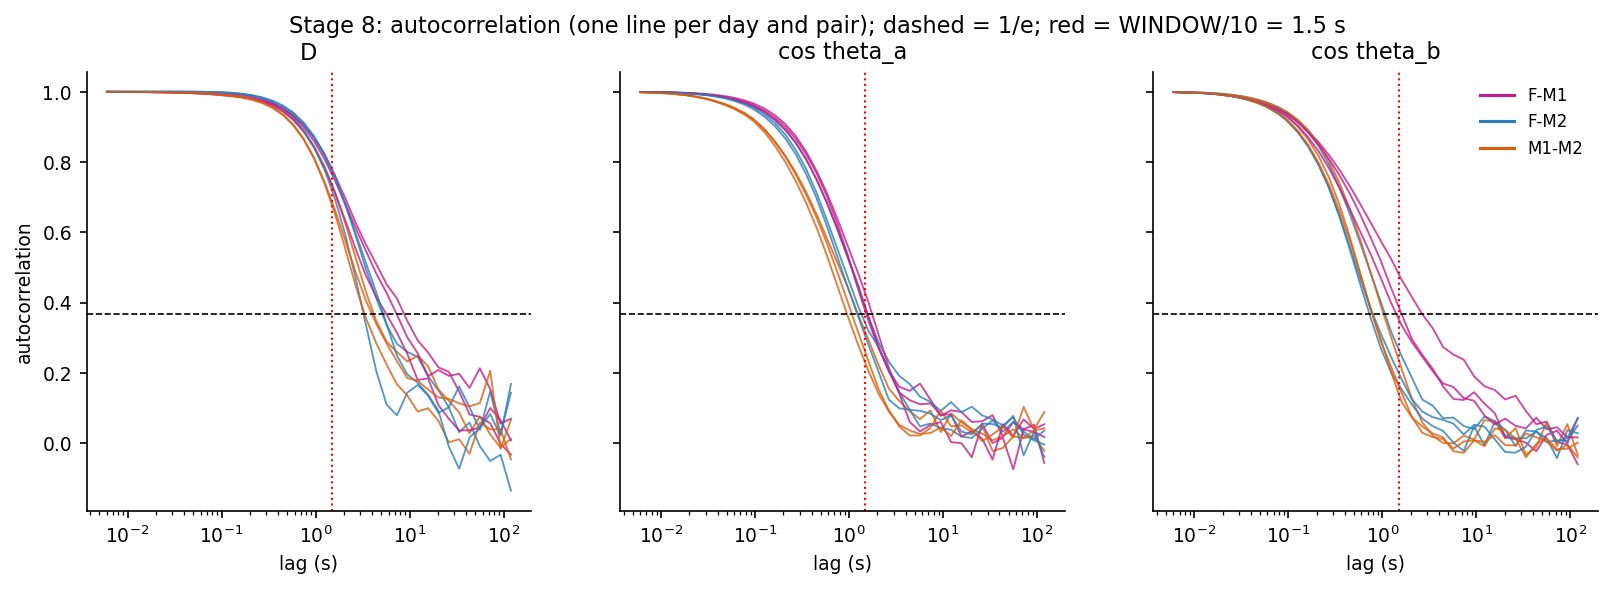

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S8_02_autocorrelation_window_choice.png


In [12]:
lags = np.unique(np.round(np.geomspace(1, int(166 * 120), 40)).astype(int))
acf_rows, curves = [], {}
for e, P in PROC.items():
    for pair in M.PAIR_NAMES:
        D, ta, tb = M.pair_units(P, pair, D_UNIT)
        for var, x in (("D", D), ("cos theta_a", np.cos(ta)), ("cos theta_b", np.cos(tb))):
            a = M.acf(x, P["seg"], lags)
            curves[(e, pair, var)] = a
            below = np.flatnonzero(a < 1 / np.e)
            tc = float(lags[below[0]] / 166) if len(below) else np.nan
            acf_rows.append({"experiment": e, "pair": pair, "variable": var, "tau_c_s": tc})
acf_tab = pd.DataFrame(acf_rows)
acf_tab.to_csv(OUT / "S8_correlation_times.csv", index=False)
print(acf_tab.pivot_table(index=["pair", "variable"], values="tau_c_s", aggfunc=["median", "min", "max"]).round(2).to_string())
tc_med = float(np.nanmedian(acf_tab["tau_c_s"]))
WINDOW_S = float(np.clip(np.round(10 * tc_med / 5) * 5, 10, 300))
print(f"median tau_c = {tc_med:.2f} s -> WINDOW_S = {WINDOW_S:.0f} s ({int(35 * 60 / WINDOW_S)} windows in a 35 min video)")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, var in zip(axes, ("D", "cos theta_a", "cos theta_b")):
    for (e, pair, v), a in curves.items():
        if v == var:
            ax.semilogx(lags / 166, a, lw=0.9, color={"F-M1": "#c51b8a", "F-M2": "#2c7fb8", "M1-M2": "#d95f0e"}[pair], alpha=0.8)
    ax.axhline(1 / np.e, color="k", ls="--", lw=0.8); ax.axvline(WINDOW_S / 10, color="r", ls=":", lw=1)
    ax.set_title(var); ax.set_xlabel("lag (s)")
axes[0].set_ylabel("autocorrelation")
for pair, c in (("F-M1", "#c51b8a"), ("F-M2", "#2c7fb8"), ("M1-M2", "#d95f0e")): axes[2].plot([], [], color=c, label=pair)
axes[2].legend(frameon=False, fontsize=8)
fig.suptitle(f"Stage 8: autocorrelation (one line per day and pair); dashed = 1/e; red = WINDOW/10 = {WINDOW_S / 10:.1f} s")
show(fig, 8, 2, "autocorrelation_window_choice")

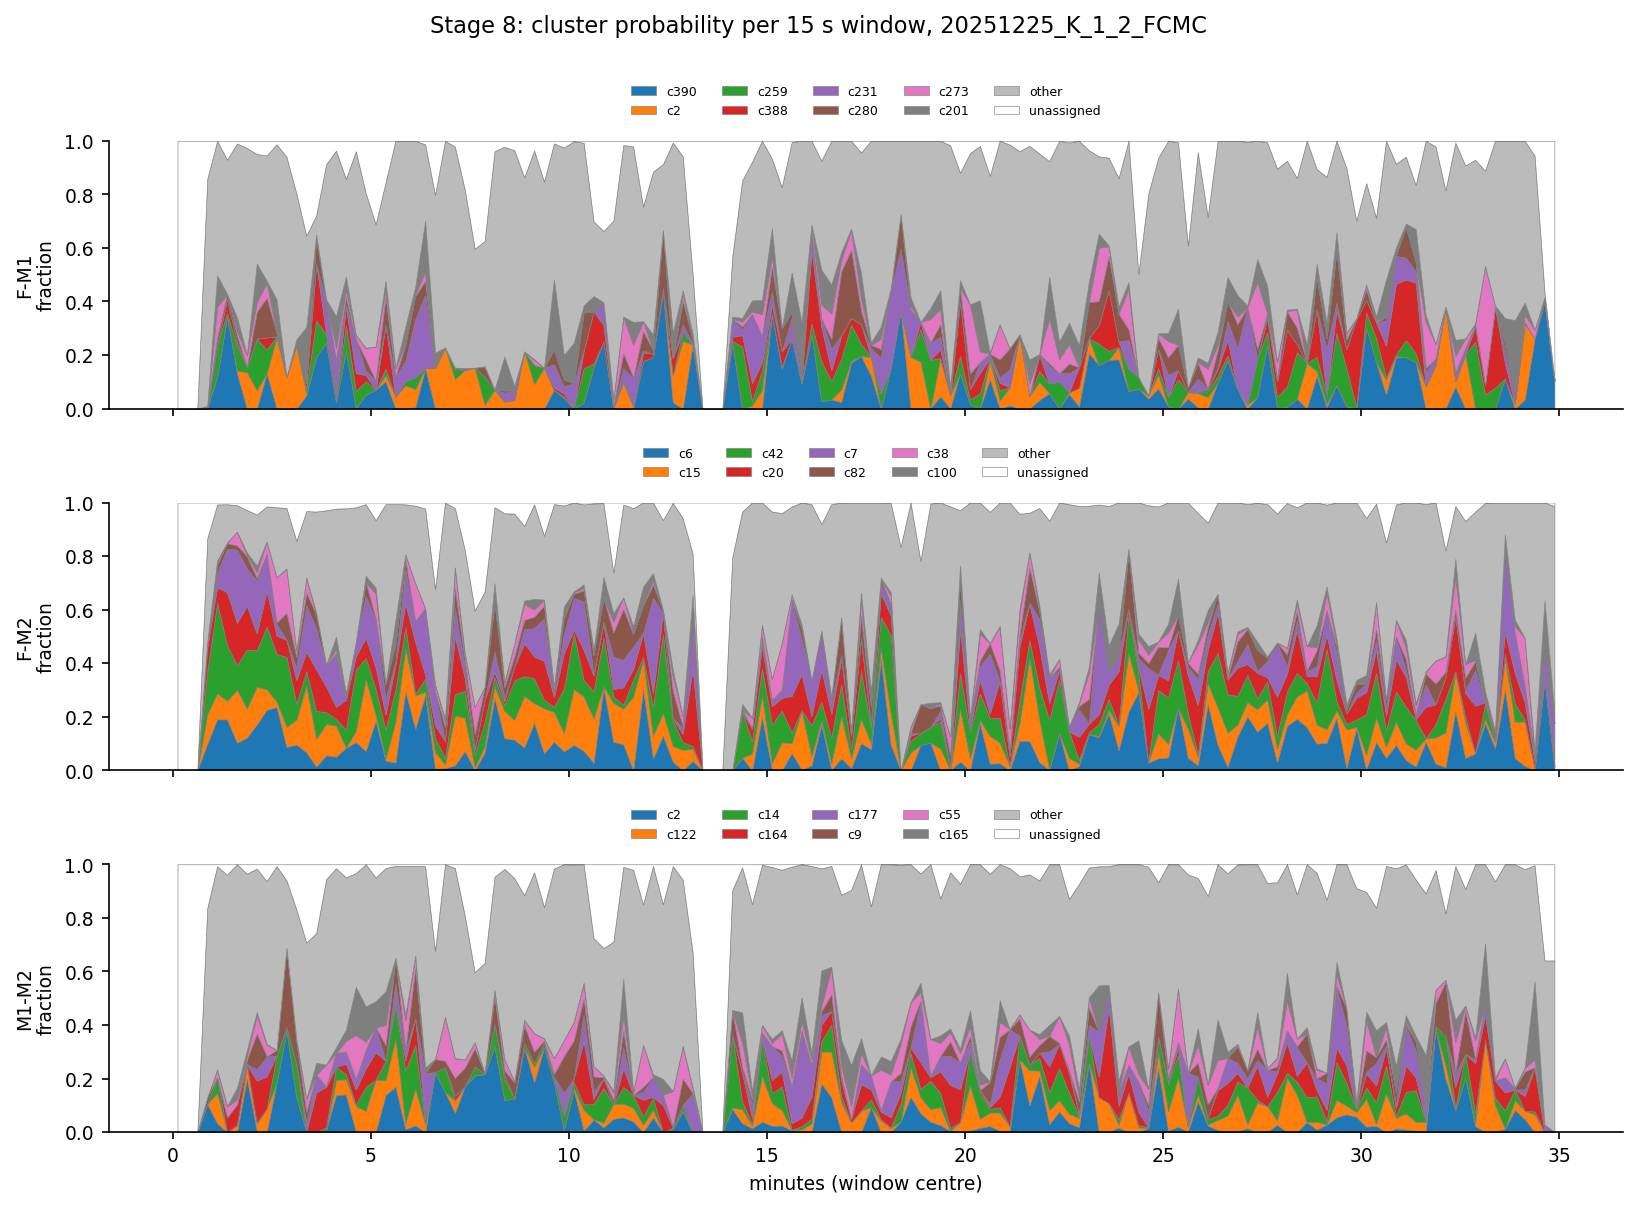

figure: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\microstate_infomap\S8_03_cluster_probability_over_time.png
{'window_s': 15.0, 'median_tau_c_s': 1.6024096385542168, 'rule': '10 x median 1/e autocorrelation time of D and cos(theta), clipped to [10, 300] s'}


In [13]:
TOP = 8
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, pair in zip(axes, M.PAIR_NAMES):
    lab = LABF[(EX, pair)]
    wn = int(WINDOW_S * fps)
    top = CL[CL["set"] == pair].head(TOP)["cluster"].tolist()
    nwin = len(lab) // wn
    frac = np.zeros((TOP + 2, nwin))
    for w in range(nwin):
        seg = lab[w * wn:(w + 1) * wn]
        for i, c in enumerate(top): frac[i, w] = np.mean(seg == c)
        frac[TOP, w] = np.mean((seg >= 0) & ~np.isin(seg, top))
        frac[TOP + 1, w] = np.mean(seg < 0)
    x = (np.arange(nwin) + 0.5) * WINDOW_S / 60
    ax.stackplot(x, frac, labels=[f"c{c}" for c in top] + ["other", "unassigned"], colors=list(plt.cm.tab10.colors[:TOP]) + ["#bbbbbb", "#ffffff"], edgecolor="0.5", linewidth=0.3)
    ax.set_ylabel(f"{pair}\nfraction"); ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=6, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.25))
axes[-1].set_xlabel("minutes (window centre)")
fig.suptitle(f"Stage 8: cluster probability per {WINDOW_S:.0f} s window, {EX}", y=1.0)
fig.tight_layout()
show(fig, 8, 3, "cluster_probability_over_time")
M.update_params("stage8", {"window_s": WINDOW_S, "median_tau_c_s": tc_med, "rule": "10 x median 1/e autocorrelation time of D and cos(theta), clipped to [10, 300] s"})
print(M.load_params()["stage8"])